In [5]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import accuracy_score,f1_score,recall_score,precision_score,confusion_matrix,classification_report

In [6]:
columns = [
    "age", "workclass", "fnlwgt", "education",
    "education-num", "marital-status", "occupation",
    "relationship", "race", "sex", "capital-gain",
    "capital-loss", "hours-per-week", "native-country",
    "income"
]

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

data = pd.read_csv(url,names=columns,skipinitialspace=True,na_values="?")

print("Dataset loaded Successfully")
print("Dataset Shape: ",data.shape)
print(data.head())

Dataset loaded Successfully
Dataset Shape:  (32561, 15)
   age         workclass  fnlwgt  education  education-num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital-status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital-gain  capital-loss  hours-per-week native-country income  
0          2174             0              40  United-St

In [7]:
print("Dataset Information: ")
data.info()
print("\n Missing Values: ")
print(data.isnull().sum())
print("\n Income DIstribution: ")
print(data["income"].value_counts())

Dataset Information: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB

 Missing Values: 
age                  0
workclass         1836
fnlwgt

In [8]:
data = data.drop_duplicates()

data["income"] = data["income"].str.strip()

data["income"] = data["income"].map({
    "<=50K": 0,
    ">50K": 1
})

data = data.dropna(subset=["income"])

X = data.drop("income", axis=1)
y = data["income"].astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print(y.value_counts())

Features shape: (32537, 14)
Target shape: (32537,)
income
0    24698
1     7839
Name: count, dtype: int64


/tmp/ipykernel_4010/3741112291.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["income"] = data["income"].str.strip()
/tmp/ipykernel_4010/3741112291.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["income"] = data["income"].map({


In [9]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical features:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 26029
Testing samples: 6508


In [11]:
numeric_transformer_lr = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

numeric_transformer_dt = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_lr = ColumnTransformer(transformers=[
    ("num", numeric_transformer_lr, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

preprocessor_dt = ColumnTransformer(transformers=[
    ("num", numeric_transformer_dt, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipelines created successfully")

Preprocessing pipelines created successfully


In [12]:
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor_lr),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully")

Logistic Regression model trained successfully


In [13]:
y_pred_lr = logistic_model.predict(X_test)

print("First 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(y_pred_lr[:10])

First 10 actual values:
[0 1 0 0 0 0 0 0 0 1]

First 10 predicted values:
[0 1 0 0 0 0 0 0 0 0]


In [14]:
tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor_dt),
    ("classifier", DecisionTreeClassifier(
        criterion="entropy",
        max_depth=5,
        random_state=42
    ))
])

tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully")

Decision Tree model trained successfully


In [15]:
y_pred_dt = tree_model.predict(X_test)

print("First 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(y_pred_dt[:10])

First 10 actual values:
[0 1 0 0 0 0 0 0 0 1]

First 10 predicted values:
[0 1 0 0 0 0 0 0 0 0]


In [16]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_dt, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_dt, zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_dt, zero_division=0)
    ]
})

print(results.round(4))

                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression    0.8566     0.7429  0.6193    0.6755
1        Decision Tree    0.8533     0.8026  0.5185    0.6300


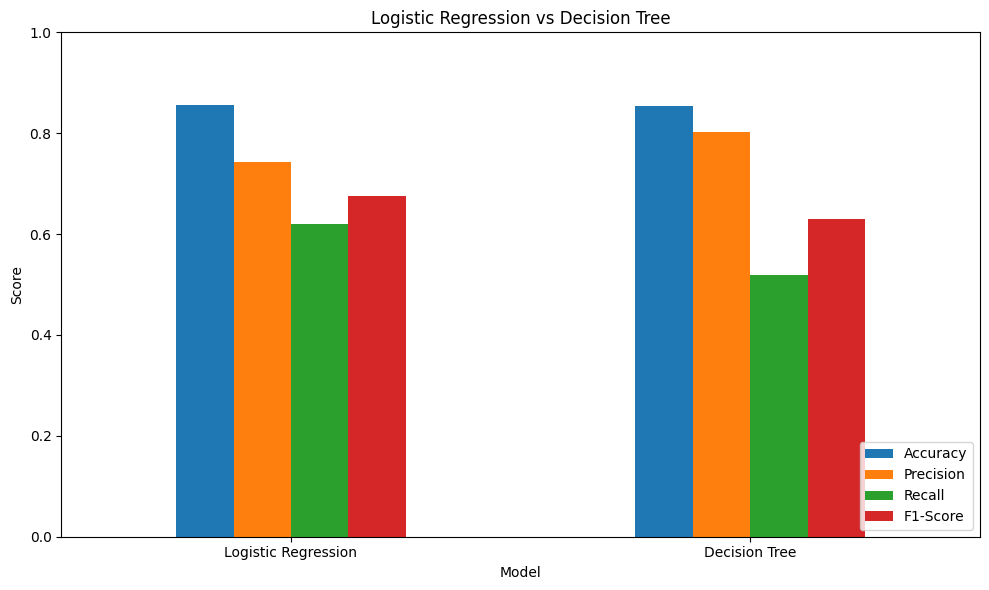

In [17]:
results.set_index("Model")[[
    "Accuracy", "Precision", "Recall", "F1-Score"
]].plot(kind="bar", figsize=(10, 6))

plt.title("Logistic Regression vs Decision Tree")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [18]:
print("LOGISTIC REGRESSION REPORT")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["<=50K", ">50K"],
    zero_division=0
))

print("\nDECISION TREE REPORT")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=["<=50K", ">50K"],
    zero_division=0
))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

       <=50K       0.89      0.93      0.91      4940
        >50K       0.74      0.62      0.68      1568

    accuracy                           0.86      6508
   macro avg       0.81      0.78      0.79      6508
weighted avg       0.85      0.86      0.85      6508


DECISION TREE REPORT
              precision    recall  f1-score   support

       <=50K       0.86      0.96      0.91      4940
        >50K       0.80      0.52      0.63      1568

    accuracy                           0.85      6508
   macro avg       0.83      0.74      0.77      6508
weighted avg       0.85      0.85      0.84      6508



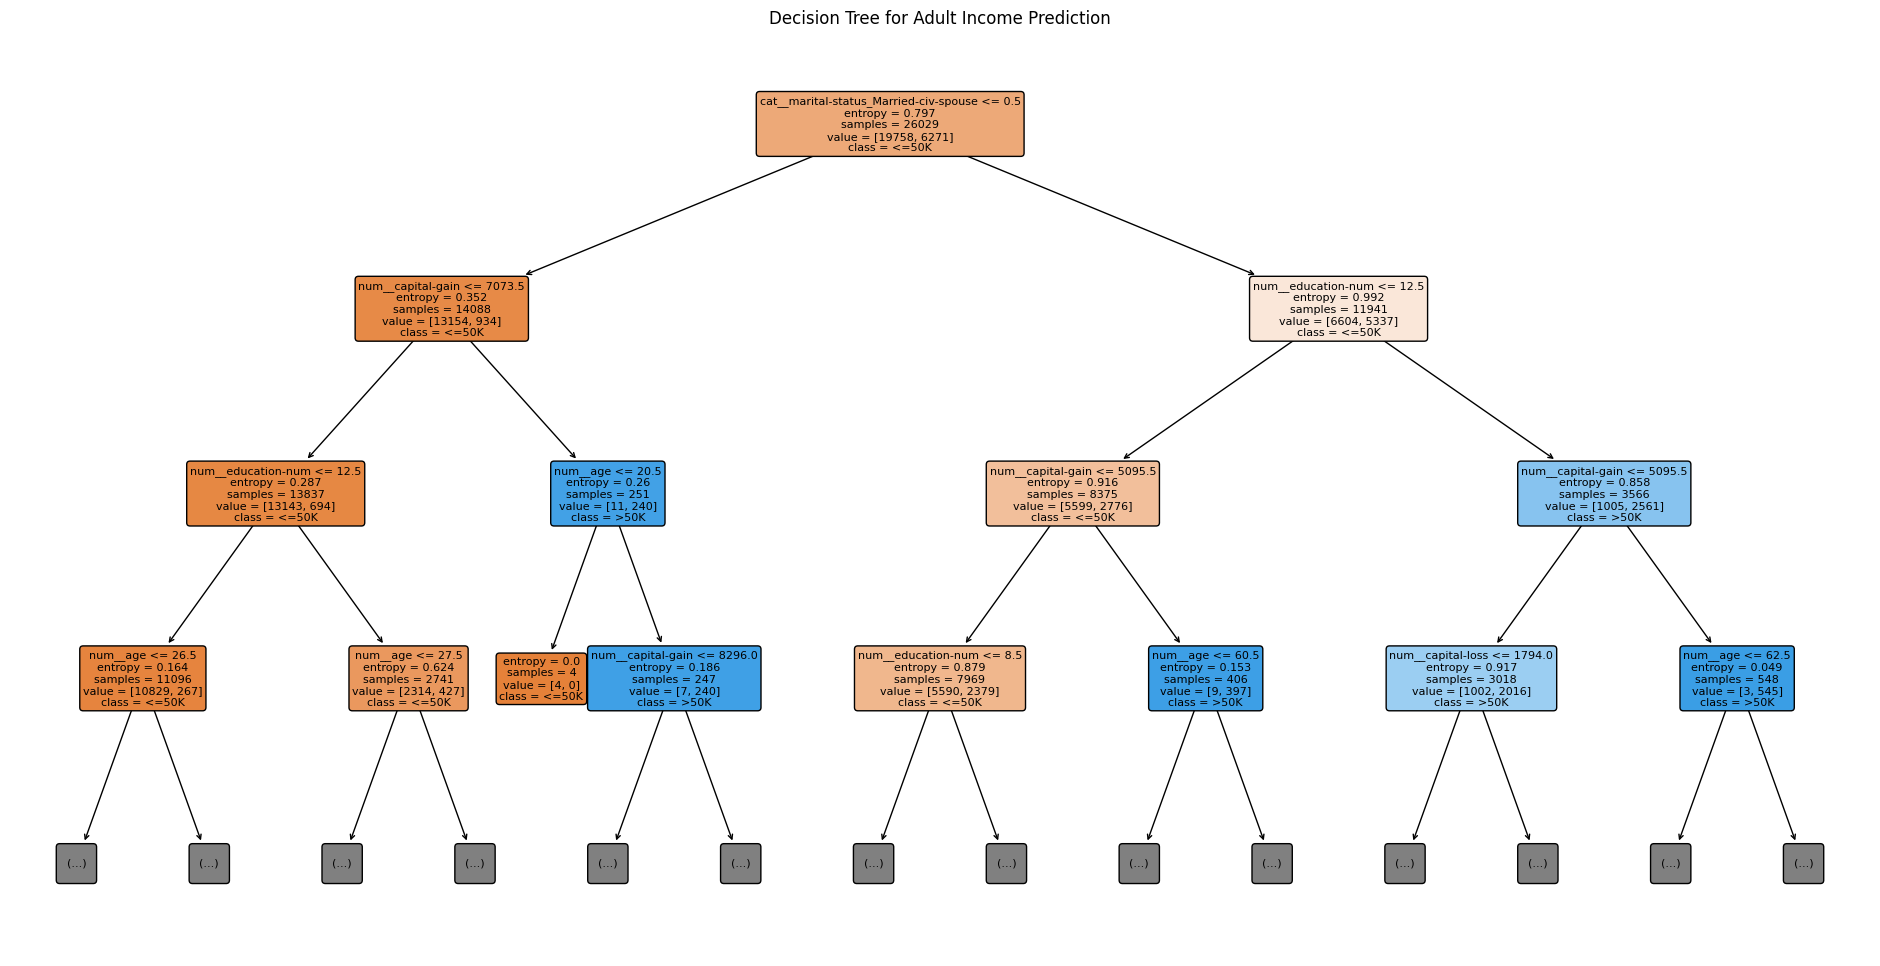

In [19]:
fitted_preprocessor = tree_model.named_steps["preprocessor"]
fitted_tree = tree_model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()

plt.figure(figsize=(24, 12))

plot_tree(
    fitted_tree,
    feature_names=feature_names,
    class_names=["<=50K", ">50K"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree for Adult Income Prediction")
plt.show()

In [20]:
importance = fitted_tree.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 important features:")
print(feature_importance.head(10))

Top 10 important features:
                                   Feature  Importance
32  cat__marital-status_Married-civ-spouse    0.464888
3                        num__capital-gain    0.214589
2                       num__education-num    0.213174
0                                 num__age    0.059759
5                      num__hours-per-week    0.024169
4                        num__capital-loss    0.021952
27                cat__education_Preschool    0.001172
11         cat__workclass_Self-emp-not-inc    0.000297
70             cat__native-country_Ecuador    0.000000
79            cat__native-country_Honduras    0.000000


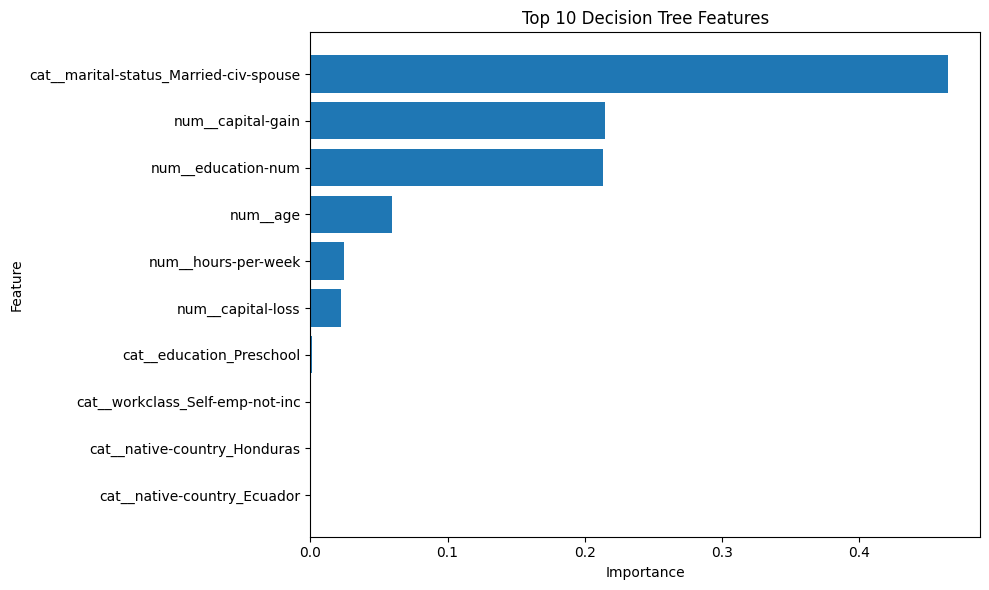

In [21]:
top_features = feature_importance.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Decision Tree Features")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

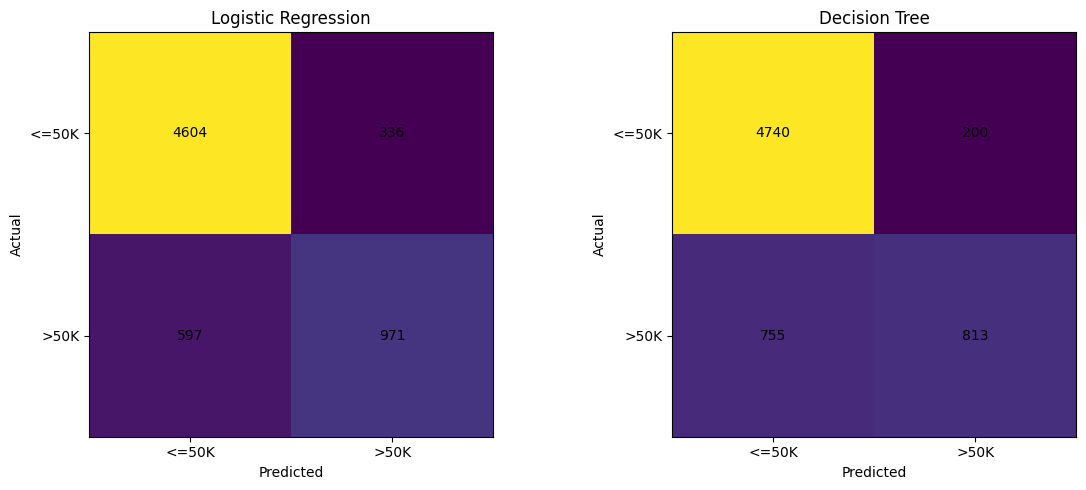

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_dt = confusion_matrix(y_test, y_pred_dt)

axes[0].imshow(cm_lr)
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(["<=50K", ">50K"])
axes[0].set_yticklabels(["<=50K", ">50K"])

for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cm_lr[i, j], ha="center", va="center")

axes[1].imshow(cm_dt)
axes[1].set_title("Decision Tree")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
axes[1].set_xticks([0, 1])
axes[1].set_yticks([0, 1])
axes[1].set_xticklabels(["<=50K", ">50K"])
axes[1].set_yticklabels(["<=50K", ">50K"])

for i in range(2):
    for j in range(2):
        axes[1].text(j, i, cm_dt[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()